# 08 · Muestreo aleatorio con NumPy

El generador moderno de NumPy (`np.random.default_rng`), los ensayos de Bernoulli, la distribución binomial, las medias muestrales y la tabla de Galton.

**Contenido**

1. El generador `Generator`
2. Ensayos de Bernoulli y la binomial
3. Medias muestrales
4. La tabla de Galton

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.stats import binom, norm

rng = np.random.default_rng(2026)

## 1. El generador `Generator`

`np.random.default_rng(semilla)` crea un generador independiente y reproducible. Sus métodos principales:

| método | resultado |
|---|---|
| `rng.random(size)` | uniformes en $[0,1)$ |
| `rng.integers(a, b, size)` | enteros en $\{a,\dots,b-1\}$ |
| `rng.choice(a, size, replace, p)` | muestra de un arreglo |
| `rng.binomial(n, p, size)` | variables $\mathrm{Bin}(n,p)$ |
| `rng.normal(mu, sigma, size)` | variables $N(\mu,\sigma^2)$ |

In [2]:
print(rng.random())
print(rng.integers(2, 7))          # entero en {2,...,6}
print(rng.integers(1, 20, size=10))

0.17893481367543618
2
[13  7  9  2  8 13  7 16 16 14]


## 2. Ensayos de Bernoulli y la binomial

Un **ensayo de Bernoulli** es un experimento con dos resultados. Para el lanzamiento de una moneda:

- espacio muestral $\Omega=\{\text{águila},\text{sol}\}$;
- variable aleatoria $X:\Omega\to\{0,1\}$ con $X(\text{sol})=1$, $X(\text{águila})=0$;
- $\mathbb{P}(X=1)=p$ y $\mathbb{P}(X=0)=1-p$, con $p\in(0,1)$.

Si $X_1,\dots,X_n$ son ensayos de Bernoulli independientes con el mismo parámetro, el número de éxitos $X_1+\cdots+X_n$ tiene ley **binomial**:

$$\mathbb{P}(X_1+\cdots+X_n=k)=\binom nk p^k(1-p)^{n-k},\qquad k=0,\dots,n.$$

`rng.binomial(1, p, size)` produce ensayos de Bernoulli. Construimos $10$ muestras de $5$ volados justos (águila $=0$, sol $=1$).

In [3]:
df = pd.DataFrame(rng.binomial(1, 0.5, size=(5, 10)),
                  columns=[f"muestra {i}" for i in range(1, 11)])
df

,muestra 1,muestra 2,muestra 3,muestra 4,muestra 5,muestra 6,muestra 7,muestra 8,muestra 9,muestra 10
0,0,1,0,1,1,1,1,1,1,0
1,0,0,0,1,0,1,0,0,0,0
2,1,0,0,0,1,1,1,0,1,1
3,0,1,0,1,0,0,1,0,0,1
4,0,1,1,1,0,0,0,0,1,1


In [4]:
medias = df.mean().rename("media muestral")
medias.to_frame().T

,muestra 1,muestra 2,muestra 3,muestra 4,muestra 5,muestra 6,muestra 7,muestra 8,muestra 9,muestra 10
media muestral,0.2,0.6,0.2,0.8,0.4,0.6,0.6,0.2,0.6,0.6


La suma de $n$ ensayos tiene la misma ley que una sola llamada a `rng.binomial(n, p)`:

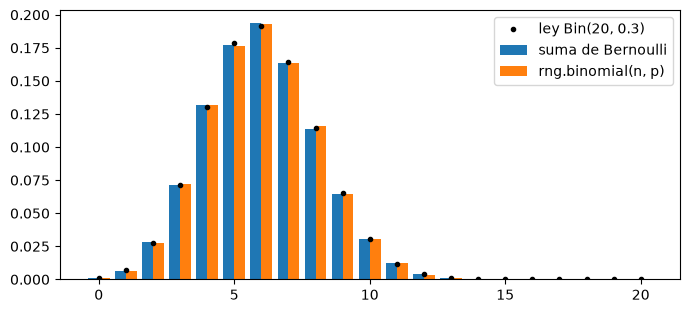

In [5]:
n, p, N = 20, 0.3, 100_000
sumas = rng.binomial(1, p, size=(N, n)).sum(axis=1)
directas = rng.binomial(n, p, size=N)
k = np.arange(n + 1)

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.bar(k - 0.2, np.bincount(sumas, minlength=n + 1) / N, width=0.4, label="suma de Bernoulli")
ax.bar(k + 0.2, np.bincount(directas, minlength=n + 1) / N, width=0.4, label="rng.binomial(n, p)")
ax.plot(k, binom.pmf(k, n, p), "k.", label="ley Bin(20, 0.3)")
ax.legend()
plt.show()

## 3. Medias muestrales

Si $X_1,\dots,X_n$ son independientes con media $\mu$ y varianza $\sigma^2$, la media muestral $\bar X_n$ tiene media $\mu$ y varianza $\sigma^2/n$. Para volados justos $\mu=\frac12$ y $\sigma^2=\frac14$. Comparamos las medias de muchas muestras de tamaño $5$ y de tamaño $50$.

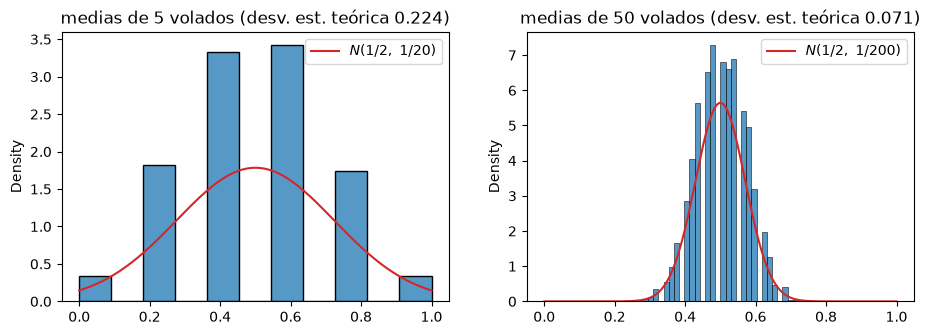

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5), sharex=True)
for ax, n in zip(axes, [5, 50]):
    medias = rng.binomial(n, 0.5, size=2000) / n
    sns.histplot(medias, stat="density", discrete=False, bins=np.linspace(0, 1, 2 * n + 2) if n == 5 else 30, ax=ax)
    x = np.linspace(0, 1, 300)
    ax.plot(x, norm.pdf(x, 0.5, np.sqrt(0.25 / n)), color="tab:red", label=rf"$N(1/2,\ 1/{4 * n})$")
    ax.set_title(f"medias de {n} volados (desv. est. teórica {np.sqrt(0.25 / n):.3f})")
    ax.legend()
plt.show()

## 4. La tabla de Galton

En la tabla de Galton (*quincunx*) una bola cae a través de $n$ filas de clavos; en cada clavo se desvía a la derecha con probabilidad $p$. La casilla final es el número de desvíos a la derecha, de modo que su ley es $\mathrm{Bin}(n,p)$. Para $n$ grande, el teorema de De Moivre–Laplace dice que esta ley se parece a la normal $N(np,\,np(1-p))$.

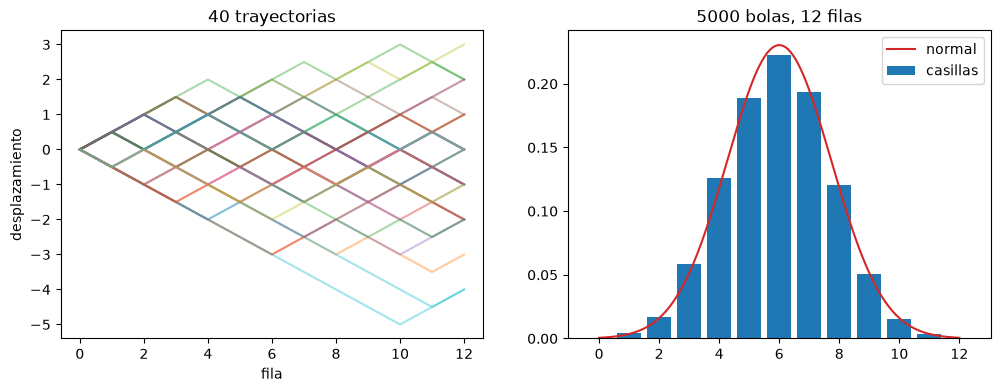

In [7]:
def galton(bolas, filas, p=0.5):
    """Trayectorias de las bolas: posición acumulada tras cada fila."""
    pasos = rng.random((bolas, filas)) < p
    return np.cumsum(pasos, axis=1)

filas, bolas = 12, 5000
trayectorias = galton(bolas, filas)
casillas = trayectorias[:, -1]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
for t in trayectorias[:40]:
    ax1.plot(range(filas + 1), np.r_[0, t] - np.arange(filas + 1) / 2, alpha=0.4)
ax1.set_xlabel("fila")
ax1.set_ylabel("desplazamiento")
ax1.set_title("40 trayectorias")

k = np.arange(filas + 1)
ax2.bar(k, np.bincount(casillas, minlength=filas + 1) / bolas, label="casillas")
x = np.linspace(0, filas, 300)
ax2.plot(x, norm.pdf(x, filas / 2, np.sqrt(filas / 4)), color="tab:red", label="normal")
ax2.set_title(f"{bolas} bolas, {filas} filas")
ax2.legend()
plt.show()

Un simulador interactivo de la tabla de Galton: [Math is Fun — Quincunx](https://www.mathsisfun.com/data/quincunx.html).

## Ejercicios

1. Repite la tabla de Galton con $p=0.3$. ¿Dónde se centra la ley de las casillas?
2. Para medias de $n$ volados, estima por simulación $\mathbb{P}(|\bar X_n-\frac12|>0.1)$ para $n=10,50,200$ y compárala con la cota de Chebyshev $\frac{1}{4n(0.1)^2}$.